# Phase 5 : profils de clients (Q1)

Ce notebook décrit la population des clients, construit une ligne de variables par client actif, puis regroupe les clients en profils avec K-means. Les fonctions sont dans `src/profiles.py`. Chaque étape est expliquée dans `docs/`.

Les clients sans transaction servent seulement à décrire la population : ils n'ont pas de comportement à résumer (règle de P2-04).

## Chargement des données

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.load_data import load_clean_table
from src.charte import (
    apply_style, save_figure, BLUE, ORANGE, NEUTRAL, TEXT_SECONDARY, THOUSANDS, diverging_cmap,
)
from src.profiles import (
    describe_population, PROFILE_INPUT_COLUMNS, build_profile_table, CLUSTER_VARIABLES,
    prepare_features, scan_kmeans, fit_profiles, profile_medians, profile_zscores,
    distinctive_traits, check_stability,
)

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [2]:
df = load_clean_table("analysis", columns=PROFILE_INPUT_COLUMNS)
df_users = load_clean_table("users")
print(f"Table d'analyse : {len(df):,} transactions ; clients : {len(df_users):,}")

Table d'analyse : 13,305,915 transactions ; clients : 2,000


## P5-01 : décrire la population des clients

Âge, genre, revenus, dette et score de crédit des 2 000 clients, en comparant les clients actifs (au moins une transaction) et les clients sans transaction.

Critère de fin : tableaux et graphiques commentés. Voir `docs/P5-01_population_clients.md`.

In [3]:
actifs = df["client_id"].unique()
population = describe_population(df_users, actifs)
population

statut,actifs,sans transaction
clients,1219.0,781.0
âge médian (février 2020),51.0,28.0
part de femmes (%),51.0,50.4
revenu annuel médian ($),40012.0,41940.0
dette médiane ($),51984.0,65126.0
score de crédit médian,715.0,705.0
cartes de crédit (médiane),4.0,2.0
revenus suspects (P3-08),11.0,4.0


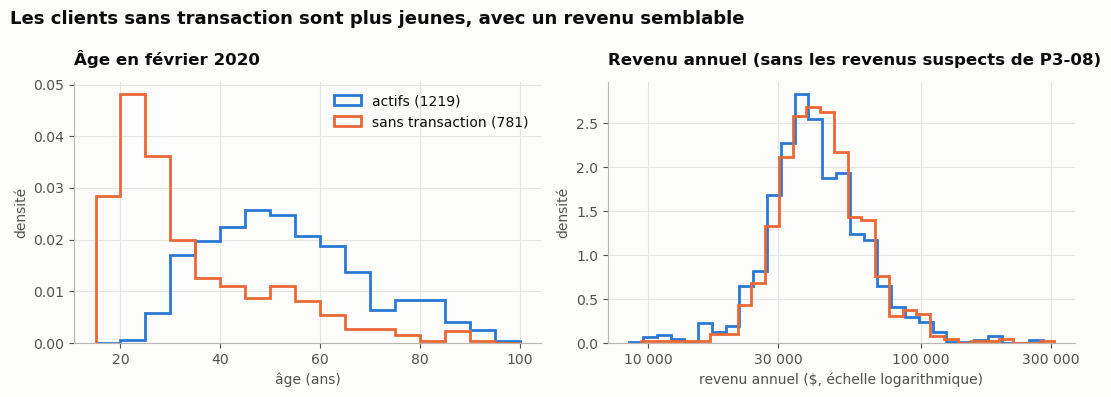

In [4]:
statut = np.where(df_users["id"].isin(actifs), "actifs", "sans transaction")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nom, couleur in [("actifs", BLUE), ("sans transaction", ORANGE)]:
    groupe = df_users[statut == nom]
    axes[0].hist(groupe["current_age"], bins=range(15, 105, 5), histtype="step", linewidth=2,
                 color=couleur, label=f"{nom} ({len(groupe)})", density=True)
    revenus = groupe.loc[groupe["suspicious_income"] == 0, "yearly_income"]
    axes[1].hist(np.log10(revenus), bins=30, histtype="step", linewidth=2, color=couleur, label=nom,
                 density=True)
axes[0].set_title("Âge en février 2020")
axes[0].set_xlabel("âge (ans)")
axes[1].set_title("Revenu annuel (sans les revenus suspects de P3-08)")
axes[1].set_xlabel("revenu annuel ($, échelle logarithmique)")
reperes = [10_000, 30_000, 100_000, 300_000]
axes[1].set_xticks(np.log10(reperes))
axes[1].set_xticklabels(["10 000", "30 000", "100 000", "300 000"])
for ax in axes:
    ax.set_ylabel("densité")
axes[0].legend()
fig.suptitle('Les clients sans transaction sont plus jeunes, avec un revenu semblable', x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_figure(fig, "P5-01_population_clients")
plt.show()

**Constats**

- 1 219 clients sont actifs et 781 n'ont aucune transaction.
- Les clients sans transaction sont beaucoup plus jeunes : âge médian de 28 ans contre 51 ans. Le graphique le confirme : la plupart ont entre 15 et 35 ans.
- Leur revenu annuel médian est proche de celui des actifs (41 940 $ contre 40 012 $), et les deux distributions de revenu se superposent.
- Ils ont une dette médiane plus élevée (65 126 $ contre 51 984 $) et moins de cartes de crédit (médiane de 2 contre 4).
- La part de femmes est la même (50,4 % et 51,0 %). Le score de crédit médian est proche (705 et 715).
- 11 clients actifs et 4 clients sans transaction ont un revenu suspect (P3-08).